# Week 1: First look at CO2 data.

In [1]:
import pandas as pd

In [2]:
url = "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv"

In [3]:
df = pd.read_csv(url)

In [4]:
df.shape

(50411, 79)

In [5]:
df[["country", "year", "co2", "co2_per_capita"]].sample(5)

,country,year,co2,co2_per_capita
30296,Monaco,1933,NaN,NaN
15041,Europe,1798,23.102,NaN
38638,Ryukyu Islands,1999,NaN,NaN
36093,Palau,1882,NaN,NaN
30756,Montserrat,1869,NaN,NaN


In [6]:
df.loc[df["country"].str.contains("Turk|Türk"), "country"].unique()

<StringArray>
['Turkey', 'Turkmenistan', 'Turks and Caicos Islands']
Length: 3, dtype: str

In [7]:
tr = df[df["country"] == "Turkey"]
tr[["year", "co2", "co2_per_capita"]].tail(10)

,year,co2,co2_per_capita
46240,2015,387.704,4.845
46241,2016,405.552,4.967
46242,2017,430.622,5.183
46243,2018,423.818,5.021
46244,2019,406.568,4.763
46245,2020,416.328,4.836
46246,2021,457.377,5.276
46247,2022,443.603,5.095
46248,2023,486.945,5.580
46249,2024,513.035,5.865


In [8]:
import matplotlib.pyplot as plt

countries = ["Turkey", "Germany", "Norway"]
subset = df[df["country"].isin(countries) & (df["year"] >= 1990)]

Matplotlib is building the font cache; this may take a moment.


In [9]:
chart = subset.pivot(index="year", columns="country", values="co2_per_capita")

<Axes: title={'center': 'CO2 emissions per person since 1990 (tonnes)'}, xlabel='year'>

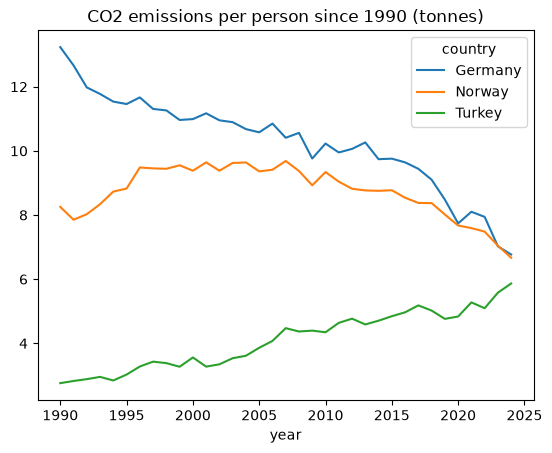

In [10]:
chart.plot(title="CO2 emissions per person since 1990 (tonnes)")

In [11]:
plt.show()

In [12]:
y2020 = df[(df["year"] == 2020) & df["iso_code"].notna() & ~df["iso_code"].str.startswith("OWID", na=False)]

In [13]:
y2020.nlargest(5, "co2_per_capita")[["country", "co2_per_capita"]]

,country,co2_per_capita
37956,Qatar,36.145
4510,Bahrain,25.238
7658,Brunei,24.937
45795,Trinidad and Tobago,23.661
47503,United Arab Emirates,22.783
